# Sesión 05 - IA en Python con cuaderno de Jupyer en Colaboratory

Instrucciones:

1. Para ejecutar una celda hay que utilizar ctrl+shift, lo cual generará el resultado del código más una nueva celda de programación.

2. Previamente a la ejecución del cuaderno, hay que verificar que tenemos conectadi la distribución de Python. Normalmente se aloja en la parte superior derecha de la interfaz de Google Colaboratory.

In [1]:
# Instalar paquetes necesarios

%pip install -U google groq openai ipywidgets

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 19.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 60.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 55.2 MB/s  0:00:00
  Attempting uninstall: widgetsnbextension
    Found existing installation: widgetsnbextension 3.6.10
    Uninstalling widgetsnbextension-3.6.10:
      Successfully uninstalled widgetsnbextension-3.6.10
  Attempting uninstall: openai
    Found existing installation: openai 2.54.0
    Uninstalling openai-2.54.0:
      Successfully uninstalled openai-2.54.0
  Attempting uninstall: ipywidgets
    Found existing installation: ipywidgets 7.7.1
    Uninstalling ipywidgets-7.7.1:
      Successfully uninstalled ipywidgets-7.7.1
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6/6 [groq]


In [2]:
# Importaciones comunes

import os
from getpass import getpass
import ipywidgets as widgets
from IPython.display import display, clear_output

In [4]:
# Elegir proveedor y preparar la clave

proveedor = "openrouter"

variables_api = {
    "gemini": "GEMINI_API_KEY",
    "groq":"GROQ_API_KEY",
    "openrouter": "OPENROUTER_API_KEY"
}

if proveedor not in variables_api:
  raise ValueError("Elige gemini, groq u openrouter.")

clave_api = os.environ.get(variables_api[proveedor], "").strip()
if not clave_api:
  clave_api = getpass(f"Clave de provedor {proveedor}: ").strip()
if not clave_api:
  raise ValueError("La clave no puede estar vacía.")

print("Proveedor seleccionado:", proveedor)

Clave de provedor openrouter: ··········
Proveedor seleccionado: openrouter


In [5]:
# Creación de la conexión

if proveedor == "gemini":
  from google import genai
  from google.genai import types
  cliente = genai.Client(
      api_key = clave_api,
      http_options={"timeout": 120000}
  )

elif proveedor == "groq":
    from groq import Groq
    cliente = Groq(api_key = clave_api, timeout = 120.0, max_retries=0)

else:
  from openai import OpenAI
  cliente = OpenAI(
      api_key = clave_api,
      base_url = "https://openrouter.ai/api/v1",
      timeout = 120.0,
      max_retries=0
  )

# La clave (api) sigue en la memoria interna del cliente, pero vamos a quitar esa copia
del clave_api
print("Cliente creado. El siguiente paso es consultar el catálogo")

Cliente creado. El siguiente paso es consultar el catálogo


In [6]:
# Consultar modelos disponibles

if proveedor == "gemini":
  catalogo = list(cliente.models.list())
  modelos = sorted(
      m.name.removeprefix("models/")
      for m in catalogo
      if "generateContent" in (m.supported_actions or [])
  )

else:
  catalogo = cliente.models.list()
  modelos = sorted(m.id for m in catalogo.data)

print("Modelos encontrados: ", len(modelos))
for nombre in modelos:
  print(nombre)

Modelos encontrados:  464
aion-labs/aion-2.0
aion-labs/aion-3.0
aion-labs/aion-3.0-mini
aion-labs/aion-3.5
aion-labs/aion-3.5-mini
aion-labs/aion-rp-llama-3.1-8b
amazon/nova-2-lite-v1
amazon/nova-lite-v1
amazon/nova-micro-v1
amazon/nova-premier-v1
amazon/nova-pro-v1
anthracite-org/magnum-v4-72b
anthropic/claude-fable-5
anthropic/claude-fable-5.1
anthropic/claude-fable-5.1:batch
anthropic/claude-fable-5:batch
anthropic/claude-haiku-4.5
anthropic/claude-haiku-4.5:batch
anthropic/claude-haiku-5.5
anthropic/claude-haiku-5.5:batch
anthropic/claude-opus-4.1
anthropic/claude-opus-4.1:batch
anthropic/claude-opus-4.5
anthropic/claude-opus-4.5:batch
anthropic/claude-opus-4.6
anthropic/claude-opus-4.6:batch
anthropic/claude-opus-4.7
anthropic/claude-opus-4.7:batch
anthropic/claude-opus-4.8
anthropic/claude-opus-4.8:batch
anthropic/claude-opus-5
anthropic/claude-opus-5.5
anthropic/claude-opus-5.5:batch
anthropic/claude-opus-5:batch
anthropic/claude-sonnet-4.5
anthropic/claude-sonnet-4.5:batch
anth

In [10]:
# Elegir mododelo y abrir una conversación

modelo = input("ID del modelo de texto/chat: ").strip()
if not modelo:
  raise ValueError("Debes indicar un modelo.")

sistema = (
    "Eres un tutor experto en Python y análisis de datos. Responde en español, "
    "paso a paso, con código separado en celdas para Jupyter. Explica supuestos "
    "e interpretación de las salidas. No inventes datos, resultados ni ejecuciones."
)

historial = [{"role": "system", "content": sistema}]

if proveedor == "gemini":
  chat = cliente.chats.create(
      model = modelo,
      config = types.GenerateContentConfig(system_instruction = sistema),
  )
print("Conversación preparada con:", proveedor, "/", modelo)

ID del modelo de texto/chat: nvidia/nemotron-3-ultra-550b-a55b
Conversación preparada con: openrouter / nvidia/nemotron-3-ultra-550b-a55b


In [11]:
# Primera consulta: Sin definir funciones

prompt = "Explica qué es un DataFrame de pandas y muestra un ejemplo con tres filas."

if proveedor == "gemini":
  respuesta = chat.send_message(prompt)
  texto = respuesta.text
else:
  mensajes = historial + [{"role": "user", "content":prompt}]
  respuesta = cliente.chat.completions.create(
      model = modelo,
      messages = mensajes
  )
  texto = respuesta.choices[0].message.content

if not texto or not texto.strip():
  raise ValueError("No se recibió texto. Revisa el modelo o el motivo de bloqueo")

if proveedor != "gemini":
  historial.extend([
      {"role": "user", "content": prompt},
      {"role": "assistant", "content":texto}
  ])

print(texto)

## ¿Qué es un DataFrame de pandas?

Un **DataFrame** es la estructura de datos principal de la librería **pandas**. Se puede entender como una **tabla bidimensional** (filas y columnas) similar a:
- Una hoja de cálculo de Excel
- Una tabla SQL
- Un diccionario de objetos Series (una columna = una Series)

### Características clave:
| Característica | Descripción |
|----------------|-------------|
| **Etiquetas** | Filas (índice) y columnas tienen etiquetas (pueden ser números, strings, fechas, etc.) |
| **Heterogeneidad** | Cada columna puede tener un tipo de dato diferente (int, float, string, bool, datetime, etc.) |
| **Tamaño mutable** | Se pueden agregar/eliminar filas y columnas después de crearlo |
| **Alineación automática** | Las operaciones entre DataFrames alinean automáticamente por etiquetas (índice/columnas) |
| **Métodos integrados** | Limpieza, transformación, agregación, join, pivot, serie temporal, E/S (CSV, Parquet, SQL, Excel, JSON…) |

---

## Ejemplo con 3 filas

V

## ¿Qué es un DataFrame de pandas?

Un **DataFrame** es la estructura de datos principal de la librería **pandas**. Se puede entender como una **tabla bidimensional** (filas y columnas) similar a:
- Una hoja de cálculo de Excel
- Una tabla SQL
- Un diccionario de objetos Series (una columna = una Series)

### Características clave:
| Característica | Descripción |
|----------------|-------------|
| **Etiquetas** | Filas (índice) y columnas tienen etiquetas (pueden ser números, strings, fechas, etc.) |
| **Heterogeneidad** | Cada columna puede tener un tipo de dato diferente (int, float, string, bool, datetime, etc.) |
| **Tamaño mutable** | Se pueden agregar/eliminar filas y columnas después de crearlo |
| **Alineación automática** | Las operaciones entre DataFrames alinean automáticamente por etiquetas (índice/columnas) |
| **Métodos integrados** | Limpieza, transformación, agregación, join, pivot, serie temporal, E/S (CSV, Parquet, SQL, Excel, JSON…) |

---

## Ejemplo con 3 filas

Vamos a crear un DataFrame pequeño que representa **tres productos** con sus **precio**, **stock** y **categoría**.

### 1. Importar pandas

```python
import pandas as pd
```

### 2. Crear el DataFrame desde un diccionario de listas

```python
data = {
    "producto": ["Teclado mecánico", "Mouse inalámbrico", "Monitor 27\""],
    "precio": [89.90, 25.50, 229.00],
    "stock": [12, 45, 7],
    "categoria": ["Periféricos", "Periféricos", "Monitores"]
}

df = pd.DataFrame(data)
df
```

### 3. Inspeccionar estructura básica

```python
# Dimensiones (filas, columnas)
df.shape
```

```python
# Tipos de datos de cada columna
df.dtypes
```

```python
# Primeras filas (aquí son todas)
df.head()
```

```python
# Estadísticas descriptivas de columnas numéricas
df.describe()
```

```python
# Información compacta (memoria, nulos, tipos)
df.info()
```

---

## Interpretación típica de las salidas

| Salida | Qué te dice |
|--------|-------------|
| `df.shape` | Tupla `(3, 4)` → 3 filas, 4 columnas |
| `df.dtypes` | `producto` y `categoria` son `object` (strings), `precio` es `float64`, `stock` es `int64` |
| `df.head()` | Muestra la tabla formateada con índice numérico 0, 1, 2 y las 4 columnas |
| `df.describe()` | Resumen estadístico de `precio` y `stock`: count, mean, std, min, 25%, 50%, 75%, max |
| `df.info()` | Resumen técnico: 3 entradas no nulas por columna, uso de memoria, tipos |

---

## Supuestos implícitos en el ejemplo

1. **Índice por defecto** → Pandas asigna un `RangeIndex(0, 1, 2)` si no se especifica otro.
2. **Tipos inferidos** → `precio` se detecta como `float64` por los decimales; `stock` como `int64`; las columnas de texto como `object`.
3. **Sin valores nulos** → Todas las listas tienen la misma longitud (3) y no hay `None`/`NaN`.
4. **Orden de columnas** → Respeta el orden del diccionario (en Python ≥3.7 los diccionarios mantienen orden de inserción).

---

## Variantes útiles de creación

```python
# 1. Desde lista de diccionarios (cada dict = una fila)
pd.DataFrame([
    {"producto": "Teclado", "precio": 89.90},
    {"producto": "Mouse", "precio": 25.50},
    {"producto": "Monitor", "precio": 229.00}
])

# 2. Desde array NumPy + nombres de columnas
import numpy as np
arr = np.array([
    ["Teclado", 89.90, 12],
    ["Mouse", 25.50, 45],
    ["Monitor", 229.00, 7]
])
pd.DataFrame(arr, columns=["producto", "precio", "stock"])

# 3. Especificando índice personalizado
pd.DataFrame(data, index=["A", "B", "C"])
```

---

## Próximos pasos típicos

- **Selección**: `df["precio"]`, `df.loc[0]`, `df.iloc[:, 1:3]`
- **Filtrado**: `df[df["stock"] < 10]`
- **Agregación**: `df.groupby("categoria")["precio"].mean()`
- **Exportación**: `df.to_csv("productos.csv", index=False)`

¿Quieres que profundice en alguna operación concreta (filtrado, groupby, join, serie temporal, etc.)?

In [12]:
from google.colab import output

output.enable_custom_widget_manager()

In [13]:
# Crear el cuadro de texto

if "panel_ia" in globals():
    panel_ia.close()

entrada = widgets.Textarea(
    value="",
    placeholder="Escribe una pregunta o pega código y explica qué necesitas…",
    description="Prompt:",
    layout=widgets.Layout(width="100%", height="180px"),
)
boton = widgets.Button(
    description="Consultar IA",
    icon="paper-plane",
    button_style="warning",
    tooltip="Enviar el prompt al proveedor seleccionado",
)
salida = widgets.Output()

print("Controles preparados. Ejecuta la siguiente celda para activar el botón.")



Controles preparados. Ejecuta la siguiente celda para activar el botón.


In [14]:
# Activar el botón: la única función

def al_consultar(b):
    pregunta = entrada.value.strip()
    with salida:
        clear_output(wait=True)
        if not pregunta:
            print("Primero escribe una pregunta.")
            return

        b.disabled = True
        b.description = "Consultando…"
        try:
            if proveedor == "gemini":
                resultado = chat.send_message(pregunta)
                texto_respuesta = resultado.text
            else:
                mensajes = historial + [{"role": "user", "content": pregunta}]
                resultado = cliente.chat.completions.create(
                    model=modelo,
                    messages=mensajes,
                )
                texto_respuesta = resultado.choices[0].message.content

            if not texto_respuesta or not texto_respuesta.strip():
                raise ValueError("Respuesta sin texto.")

            if proveedor != "gemini":
                historial.extend([
                    {"role": "user", "content": pregunta},
                    {"role": "assistant", "content": texto_respuesta},
                ])
            print(texto_respuesta)

        except Exception as error:
            print("No se completó la consulta:", type(error).__name__)
            print("Revisa clave, modelo, permisos, cuota y conexión.")
        finally:
            b.disabled = False
            b.description = "Consultar IA"

In [15]:
# Evita registrar el mismo evento varias veces al repetir esta celda.
if "evento_ia" in globals():
    boton.on_click(evento_ia, remove=True)
evento_ia = al_consultar
boton.on_click(evento_ia)

if "panel_ia" in globals():
    panel_ia.close()
panel_ia = widgets.VBox([entrada, boton, salida])
display(panel_ia)

Columnas disponibles: ['Adj Close', 'Close', 'High', 'Low', 'Open', 'Volume']
Tipos de datos:
 Adj Close    float64
Close        float64
High         float64
Low          float64
Open         float64
Volume         int64
dtype: object
Primeras 5 filas:
             Adj Close      Close       High        Low       Open     Volume
Date                                                                        
2018-01-02  40.232380  43.064999  43.075001  42.314999  42.540001  102223600
2018-01-03  40.225353  43.057499  43.637501  42.990002  43.132500  118071600
2018-01-04  40.412216  43.257500  43.367500  43.020000  43.134998   89738400
2018-01-05  40.872326  43.750000  43.842499  43.262501  43.360001   94640000
2018-01-08  40.720512  43.587502  43.902500  43.482498  43.587502   82271200


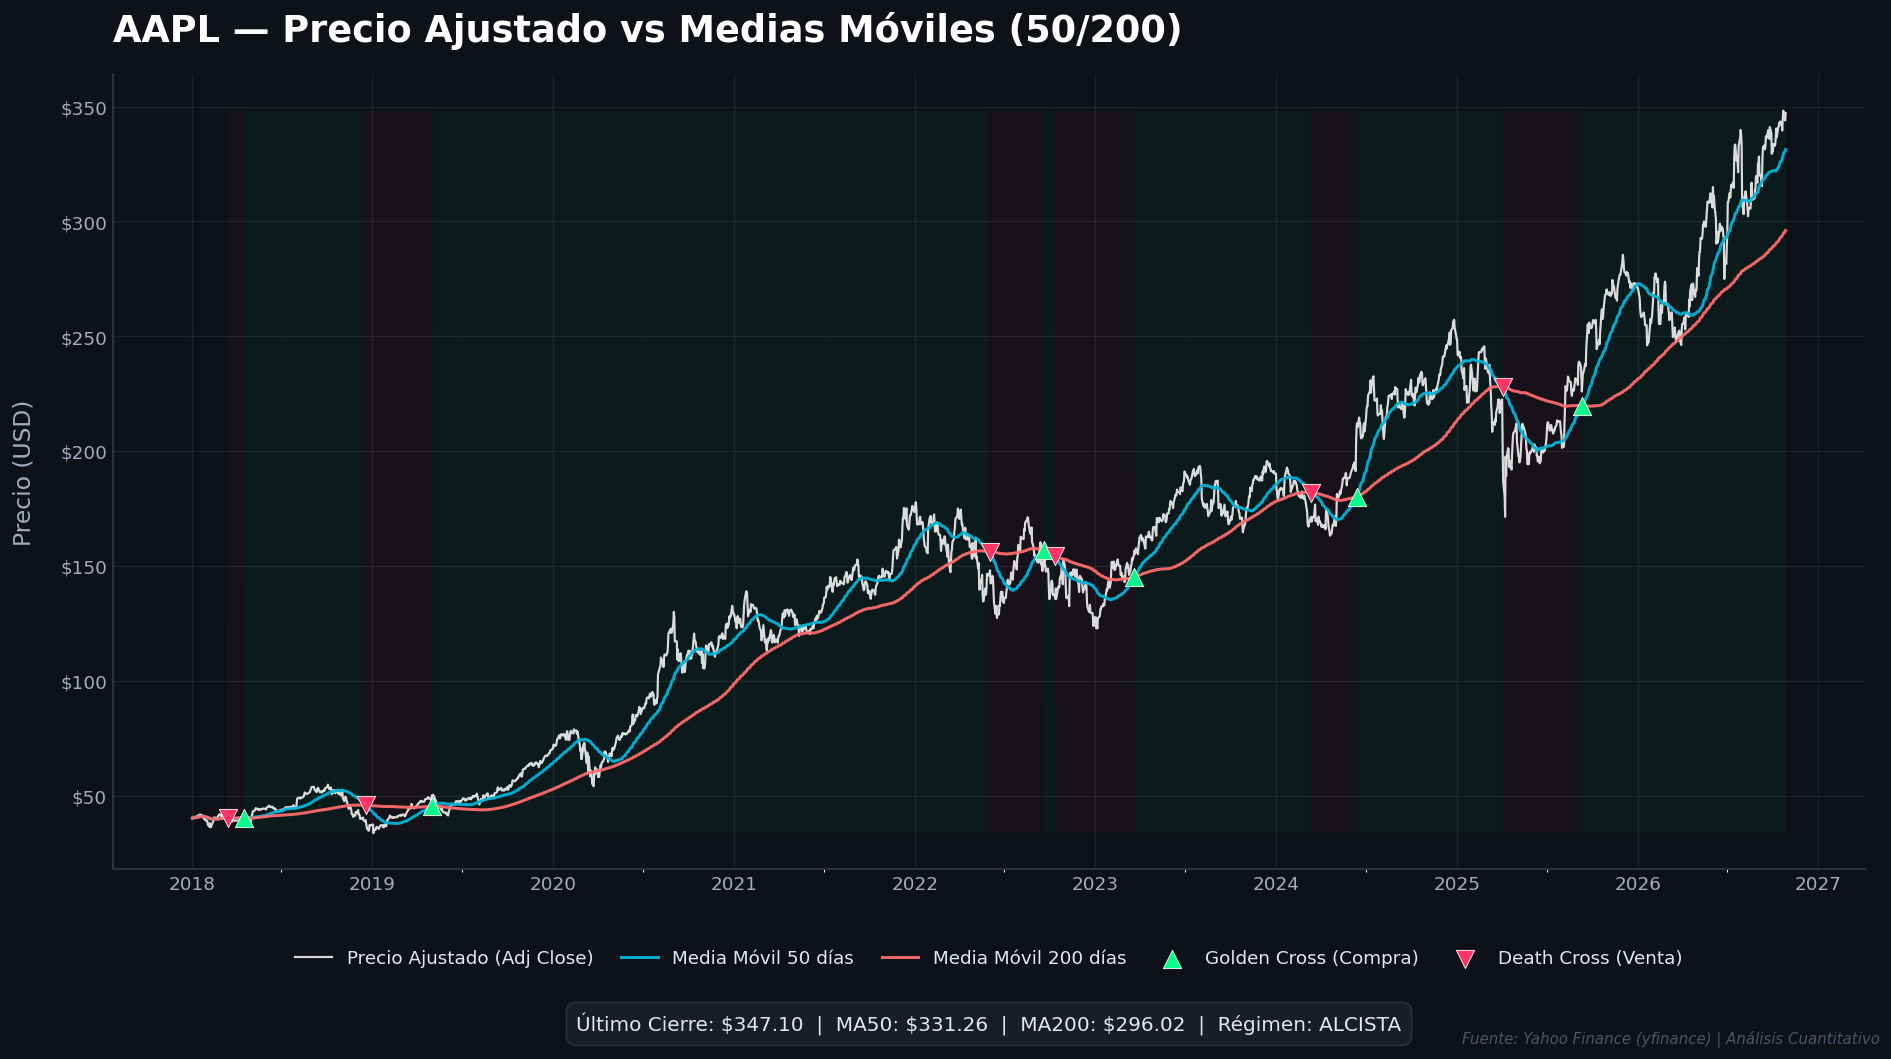


--- Resumen AAPL (2026-10-27) ---
Adj Close: $347.10
MA 50:     $331.26
MA 200:    $296.02
Spread 50/200: +11.90%
Régimen actual: ALCISTA


In [17]:
import yfinance as yf
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.ticker as mticker
import numpy as np

# 1. Descarga de datos
ticker = "AAPL"
df = yf.download(ticker, start="2018-01-01", auto_adjust=False, multi_level_index=False, progress=False)

# 2. Inspección de columnas (se imprime en salida de la celda)
print("Columnas disponibles:", df.columns.tolist())
print("Tipos de datos:\n", df.dtypes)
print("Primeras 5 filas:\n", df.head())

# 3. Preparación de datos
# yfinance con auto_adjust=False devuelve columnas: Open, High, Low, Close, Adj Close, Volume
# Nos aseguramos de que el índice sea DatetimeIndex y ordenado
df = df.asfreq('B').ffill()  # Rellena huecos de fines de semana/festivos para ventanas móviles exactas
df.index.name = "Fecha"

# Extraer serie objetivo
close = df["Adj Close"].copy()

# 4. Cálculo de medias móviles
df["MA_50"] = close.rolling(window=50, min_periods=1).mean()
df["MA_200"] = close.rolling(window=200, min_periods=1).mean()

# 5. Configuración de estilo profesional "Dark Mode" alta calidad
plt.style.use('dark_background')
fig, ax = plt.subplots(figsize=(16, 9), dpi=120, facecolor='#0e1117')
ax.set_facecolor('#0e1117')

# Paleta de colores de alto contraste (accesible)
color_price = '#ffffff'      # Blanco puro para precio
color_ma50  = '#00b4d8'      # Cian brillante
color_ma200 = '#ff6b6b'      # Rojo coral
color_buy   = '#00ff88'      # Verde neón (cruce alcista)
color_sell  = '#ff3366'      # Rosa neón (cruce bajista)
grid_color = '#2d333b'

# 6. Gráfico principal
# Precio Ajustado
ax.plot(df.index, close, label='Precio Ajustado (Adj Close)', color=color_price, linewidth=1.3, alpha=0.85, zorder=3)
# MA 50
ax.plot(df.index, df["MA_50"], label='Media Móvil 50 días', color=color_ma50, linewidth=1.8, alpha=0.95, zorder=4)
# MA 200
ax.plot(df.index, df["MA_200"], label='Media Móvil 200 días', color=color_ma200, linewidth=1.8, alpha=0.95, zorder=4)

# 7. Detección y marcado de Cruces (Golden Cross / Death Cross)
# Señal: MA50 cruza MA200
cross_up   = (df["MA_50"].shift(1) < df["MA_200"].shift(1)) & (df["MA_50"] > df["MA_200"])
cross_down = (df["MA_50"].shift(1) > df["MA_200"].shift(1)) & (df["MA_50"] < df["MA_200"])

ax.scatter(df.index[cross_up], df["MA_50"][cross_up],
           marker='^', color=color_buy, s=120, label='Golden Cross (Compra)', zorder=5, edgecolors='white', linewidths=0.5)
ax.scatter(df.index[cross_down], df["MA_50"][cross_down],
           marker='v', color=color_sell, s=120, label='Death Cross (Venta)', zorder=5, edgecolors='white', linewidths=0.5)

# 8. Sombreado de régimen (Alcista/Bajista)
bull_mask = df["MA_50"] > df["MA_200"]
bear_mask = df["MA_50"] < df["MA_200"]
ax.fill_between(df.index, close.min(), close.max(), where=bull_mask, facecolor=color_buy, alpha=0.04, interpolate=True)
ax.fill_between(df.index, close.min(), close.max(), where=bear_mask, facecolor=color_sell, alpha=0.04, interpolate=True)

# 9. Formato de ejes y estética
# Título y etiquetas
ax.set_title(f"{ticker} — Precio Ajustado vs Medias Móviles (50/200)", fontsize=22, fontweight='bold', color='#ffffff', pad=20, loc='left')
ax.set_ylabel("Precio (USD)", fontsize=14, color='#a0aec0', labelpad=15)
ax.set_xlabel("")

# Eje Y: Formato moneda con separador de miles
ax.yaxis.set_major_formatter(mticker.StrMethodFormatter('${x:,.0f}'))
ax.tick_params(axis='y', labelsize=11, colors='#a0aec0', length=0)
ax.tick_params(axis='x', labelsize=11, colors='#a0aec0', length=0)

# Eje X: Formato de fecha inteligente
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
ax.xaxis.set_minor_locator(mdates.MonthLocator((1, 7)))
fig.autofmt_xdate(rotation=0, ha='center')

# Grid
ax.grid(True, which='major', color=grid_color, linewidth=0.8, linestyle='-', alpha=0.5)
ax.grid(True, which='minor', color=grid_color, linewidth=0.4, linestyle=':', alpha=0.3)
ax.set_axisbelow(True)

# Spines (bordes)
for spine in ['top', 'right']:
    ax.spines[spine].set_visible(False)
for spine in ['bottom', 'left']:
    ax.spines[spine].set_color(grid_color)
    ax.spines[spine].set_linewidth(1.2)

# Leyenda fuera del gráfico, estilo limpio
legend = ax.legend(
    loc='upper center', bbox_to_anchor=(0.5, -0.08),
    ncol=5, frameon=False, fontsize=11,
    labelcolor='#e2e8f0', handlelength=2.0, columnspacing=1.5
)

# Anotación del último precio y MAs (Dashboard style)
last_date = df.index[-1]
last_price = close.iloc[-1]
last_ma50 = df["MA_50"].iloc[-1]
last_ma200 = df["MA_200"].iloc[-1]
regime = "ALCISTA" if last_ma50 > last_ma200 else "BAJISTA 📉"
regime_color = color_buy if last_ma50 > last_ma200 else color_sell

text_str = (f"Último Cierre: ${last_price:,.2f}  |  MA50: ${last_ma50:,.2f}  |  MA200: ${last_ma200:,.2f}  |  Régimen: {regime}")
ax.text(0.5, -0.18, text_str, transform=ax.transAxes, fontsize=12, ha='center', va='top',
        color='#e2e8f0', bbox=dict(boxstyle='round,pad=0.5', facecolor='#1a1f2b', edgecolor=grid_color, alpha=0.9))

# Watermark / Fuente
fig.text(0.99, 0.01, 'Fuente: Yahoo Finance (yfinance) | Análisis Cuantitativo',
         ha='right', va='bottom', fontsize=9, color='#4a5568', fontstyle='italic')

plt.tight_layout(pad=2.0)
plt.show()

# 10. Resumen numérico final en consola
print(f"\n--- Resumen {ticker} ({last_date.strftime('%Y-%m-%d')}) ---")
print(f"Adj Close: ${last_price:,.2f}")
print(f"MA 50:     ${last_ma50:,.2f}")
print(f"MA 200:    ${last_ma200:,.2f}")
print(f"Spread 50/200: {((last_ma50 - last_ma200)/last_ma200)*100:+.2f}%")
print(f"Régimen actual: {regime}")

[*********************100%***********************]  1 of 1 completed


Columnas disponibles: ['Adj Close', 'Close', 'High', 'Low', 'Open', 'Volume']


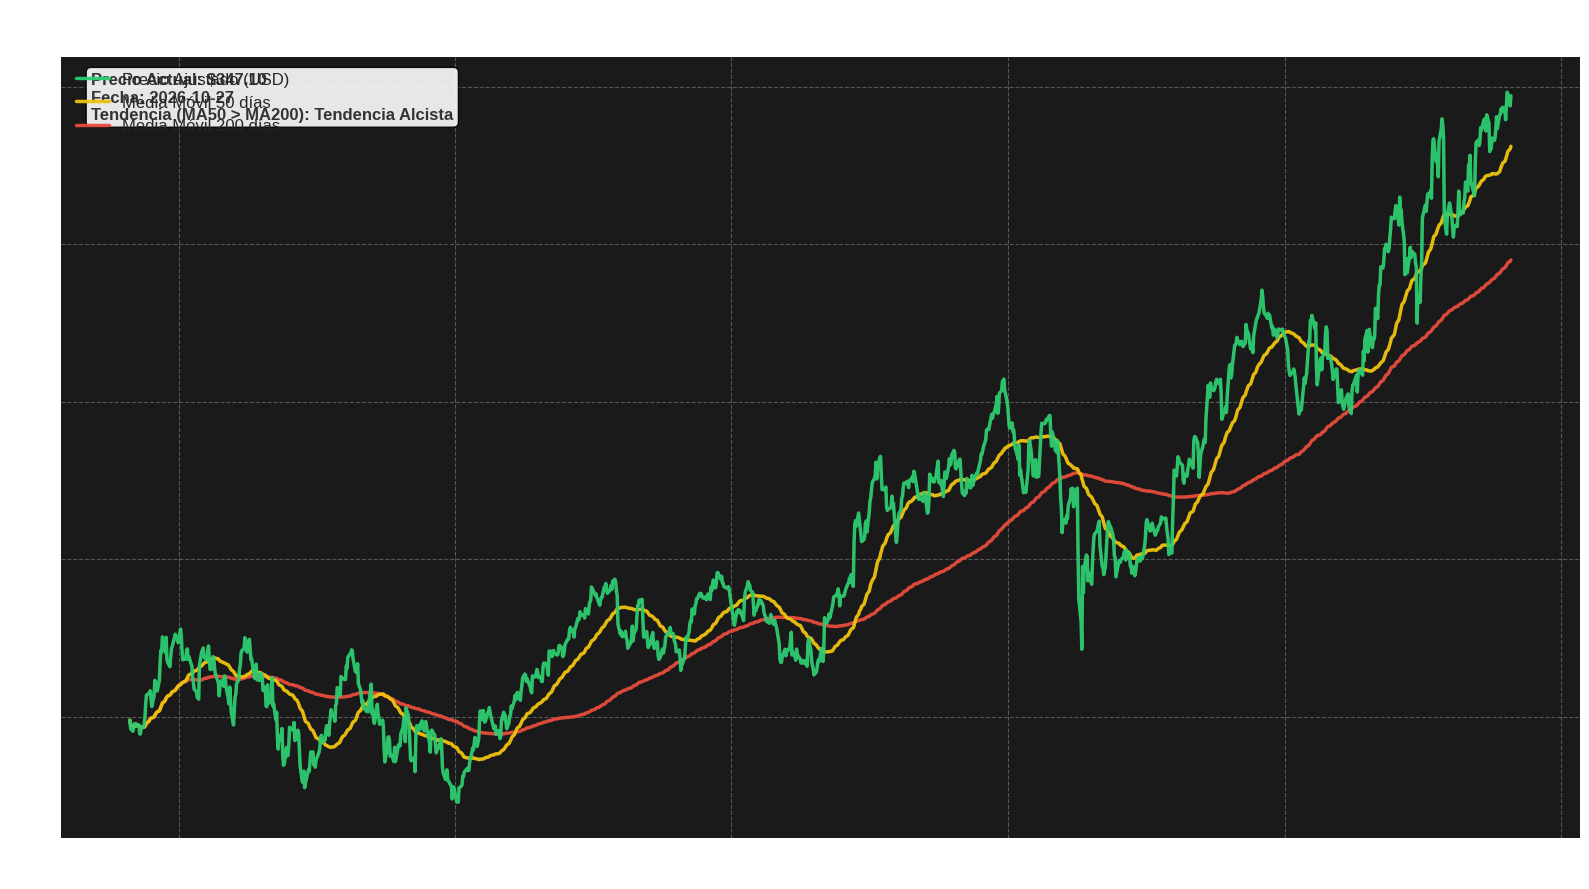

In [20]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import yfinance as yf

# Descargar datos de AAPL
ticker = 'AAPL'
period = '5y'
data = yf.download(ticker, period=period, auto_adjust=False, multi_level_index=False)

# Revisar columnas disponibles
print(f"Columnas disponibles: {data.columns.tolist()}")
if 'Adj Close' not in data.columns:
    raise ValueError("La columna 'Adj Close' no existe en los datos descargados.")

# Extraer Precio Ajustado y calcular medias móviles
df = data[['Adj Close']].copy()
df['MA50'] = df['Adj Close'].rolling(window=50, min_periods=1).mean()
df['MA200'] = df['Adj Close'].rolling(window=200, min_periods=1).mean()

# Preparar el gráfico con diseño profesional y alto impacto visual
plt.style.use('seaborn-v0_8-darkgrid')

fig, ax = plt.subplots(figsize=(16, 9))

# Definir paleta de colores
color_price = '#2ecc71'
color_ma50 = '#f1c40f'
color_ma200 = '#e74c3c'

# Plotear las series
ax.plot(df.index, df['Adj Close'], color=color_price, linewidth=2.5,
         label='Precio Ajustado (USD)', alpha=0.95, zorder=3)
ax.plot(df.index, df['MA50'], color=color_ma50, linewidth=2.5,
         label='Media Móvil 50 días', alpha=0.95, zorder=2)
ax.plot(df.index, df['MA200'], color=color_ma200, linewidth=2.5,
         label='Media Móvil 200 días', alpha=0.95, zorder=1)

# Estilizar el gráfico
ax.set_title(f'Análisis Técnico: {ticker} ({period})', fontsize=20,
fontweight='bold', pad=20, color='white')
ax.set_xlabel('Fecha', fontsize=14, fontweight='bold', color='white')
ax.set_ylabel('Precio Ajustado (USD)', fontsize=14, fontweight='bold',
color='white')
ax.set_facecolor('#1a1a1a')
ax.tick_params(colors='white', labelcolor='white', axis='both')
ax.grid(True, linestyle='--', linewidth=0.8, color='gray', alpha=0.6)
ax.legend(loc='upper left', fontsize=12, framealpha=0.9, edgecolor='black')

# Añadir caja de información con precio actual y tendencia
current_price = df['Adj Close'].iloc[-1]
current_date = df.index[-1]
ma50 = df['MA50'].iloc[-1]
ma200 = df['MA200'].iloc[-1]
trend = "Tendencia Alcista" if ma50 > ma200 else "Tendencia Bajista"

text_box = f"Precio Actual: ${current_price:.2f}\nFecha: {current_date.strftime("%Y-%m-%d")}\nTendencia (MA50 > MA200): {trend}"

props = {'boxstyle': 'round,pad=0.5', 'facecolor': 'white', 'alpha': 0.9,
'edgecolor': 'black', 'linewidth': 2}
ax.text(0.02, 0.98, text_box, transform=ax.transAxes, fontsize=12,
        verticalalignment='top', fontweight='bold', color='#333333',
        bbox=dict(boxstyle='round', facecolor='white', alpha=0.9,
edgecolor='black'))

# Ajustar layout
plt.tight_layout()
plt.show()